In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import scienceplots


plt.style.use(['science', 'ieee'])
sns.set_style("whitegrid")  # Choose your style
sns.set_context("paper")    



In [7]:
import torch
import numpy as np

class TrajectoryGenerator:
    def __init__(self, device):
        self.device = device
        self.time = 0.0
        self.params = {
            'circle': {'radius': 5, 'height': 0.0, 'speed': 0.4},
            'lemniscate': {'a': 2.5, 'height': 2.0, 'speed': 0.4},
            'slalom': {'length': 4.0, 'width': 1.0, 'height': 2.0, 'speed': 0.6},
            'helix': {'radius': 1.0, 'height_speed': 0.3, 'speed': 0.5}
        }

        self.center = (0.0, 0.0, 1.0)  # Default center for trajectories

    def reset(self):
        self.time = 0.0

    def update(self, dt):
        self.time += dt

    def circle(self, t, center=(0.0, 0.0, 1.0)):
        r = self.params['circle']['radius']
        h = self.params['circle']['height']
        freq = self.params['circle']['speed']
        x = center[0] + r * torch.cos(2 * torch.pi * freq * t)
        y = center[1] + r * torch.sin(2 * torch.pi * freq * t)
        z = center[2] + h * torch.sin(2 * torch.pi * freq * t)
        return torch.stack((x, y, z), dim=1).squeeze()

    def lemniscate(self, t, center=(0.0, 0.0, 1.0)):
        a = self.params['lemniscate']['a']
        freq = self.params['lemniscate']['speed']
        scale = 1 / (1 + torch.sin(2 * torch.pi * freq * t)**2)
        x = center[0] + a * torch.cos(2 * torch.pi * freq * t) * scale
        y = center[1] + a * torch.sin(4 * torch.pi * freq * t) * scale
        z = center[2] + 0.0 * torch.sin(3 * torch.pi * freq * t)
        return torch.stack((x, y, z), dim=1).squeeze()

    def slalom(self, t, center=(0.0, 0.0, 1.0)):
        L = self.params['slalom']['length']
        w = self.params['slalom']['width']
        freq = self.params['slalom']['speed']
        x = center[0] + w * torch.sin(2 * torch.pi * freq * t)
        y = center[1] + L * torch.cos(2 * torch.pi * freq * t)
        z = center[2] + 0.0 * torch.cos(4 * torch.pi * freq * t)
        return torch.stack((x, y, z), dim=1).squeeze()

    def helix(self, t, center=(0.0, 0.0, 1.0)):
        r = self.params['helix']['radius']
        freq = self.params['helix']['speed']
        h_speed = self.params['helix']['height_speed']
        x = center[0] + r * torch.cos(2 * torch.pi * freq * t)
        y = center[1] + r * torch.sin(2 * torch.pi * freq * t)
        z = center[2] + h_speed * t
        return torch.stack((x, y, z), dim=1).squeeze()

    def generate_trajectory(self, trajectory_type, time):
        self.time = time
        if trajectory_type == "circle":
            pos = self.circle(self.time)
        elif trajectory_type == "lemniscate":
            pos = self.lemniscate(self.time)
        elif trajectory_type == "slalom":
            pos = self.slalom(self.time)
        elif trajectory_type == "helix":
            pos = self.helix(self.time)
        else:  # Default to hover
            pos = torch.tensor([0.0, 0.0, 1.0])
        
        # Convert to tensor and repeat for all environments
        # pos_tensor = torch.tensor(pos, device=self.device)

        # Identity quaternion for orientation (w, x, y, z)
        quat_tensor = torch.tensor([1.0, 0.0, 0.0, 0.0], device=self.device)
        # return pos_tensor, quat_tensor
        return pos.to(device=self.device)

In [8]:
# plot all in subfigures
import matplotlib.pyplot as plt
def plot_trajectory(generator, trajectory_type, time_range):
    times = torch.linspace(0, time_range, 100)
    positions = [generator.generate_trajectory(trajectory_type, t) for t in times]
    positions = torch.stack(positions)

    plt.figure(figsize=(10, 6))
    plt.plot(positions[:, 0].cpu().numpy(), positions[:, 1].cpu().numpy(), label=trajectory_type)
    plt.title(f"{trajectory_type.capitalize()} Trajectory")
    plt.xlabel("X Position")
    plt.ylabel("Y Position")
    plt.grid()
    plt.legend()
    plt.axis('equal')
    plt.show()


    

In [9]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
T = torch.linspace(0, 10, 1000)

generator = TrajectoryGenerator(device)
# 
# torch.sum(T, dim=1)

In [10]:
points = generator.generate_trajectory("circle", T)
print(points.shape)

torch.Size([1000, 3])


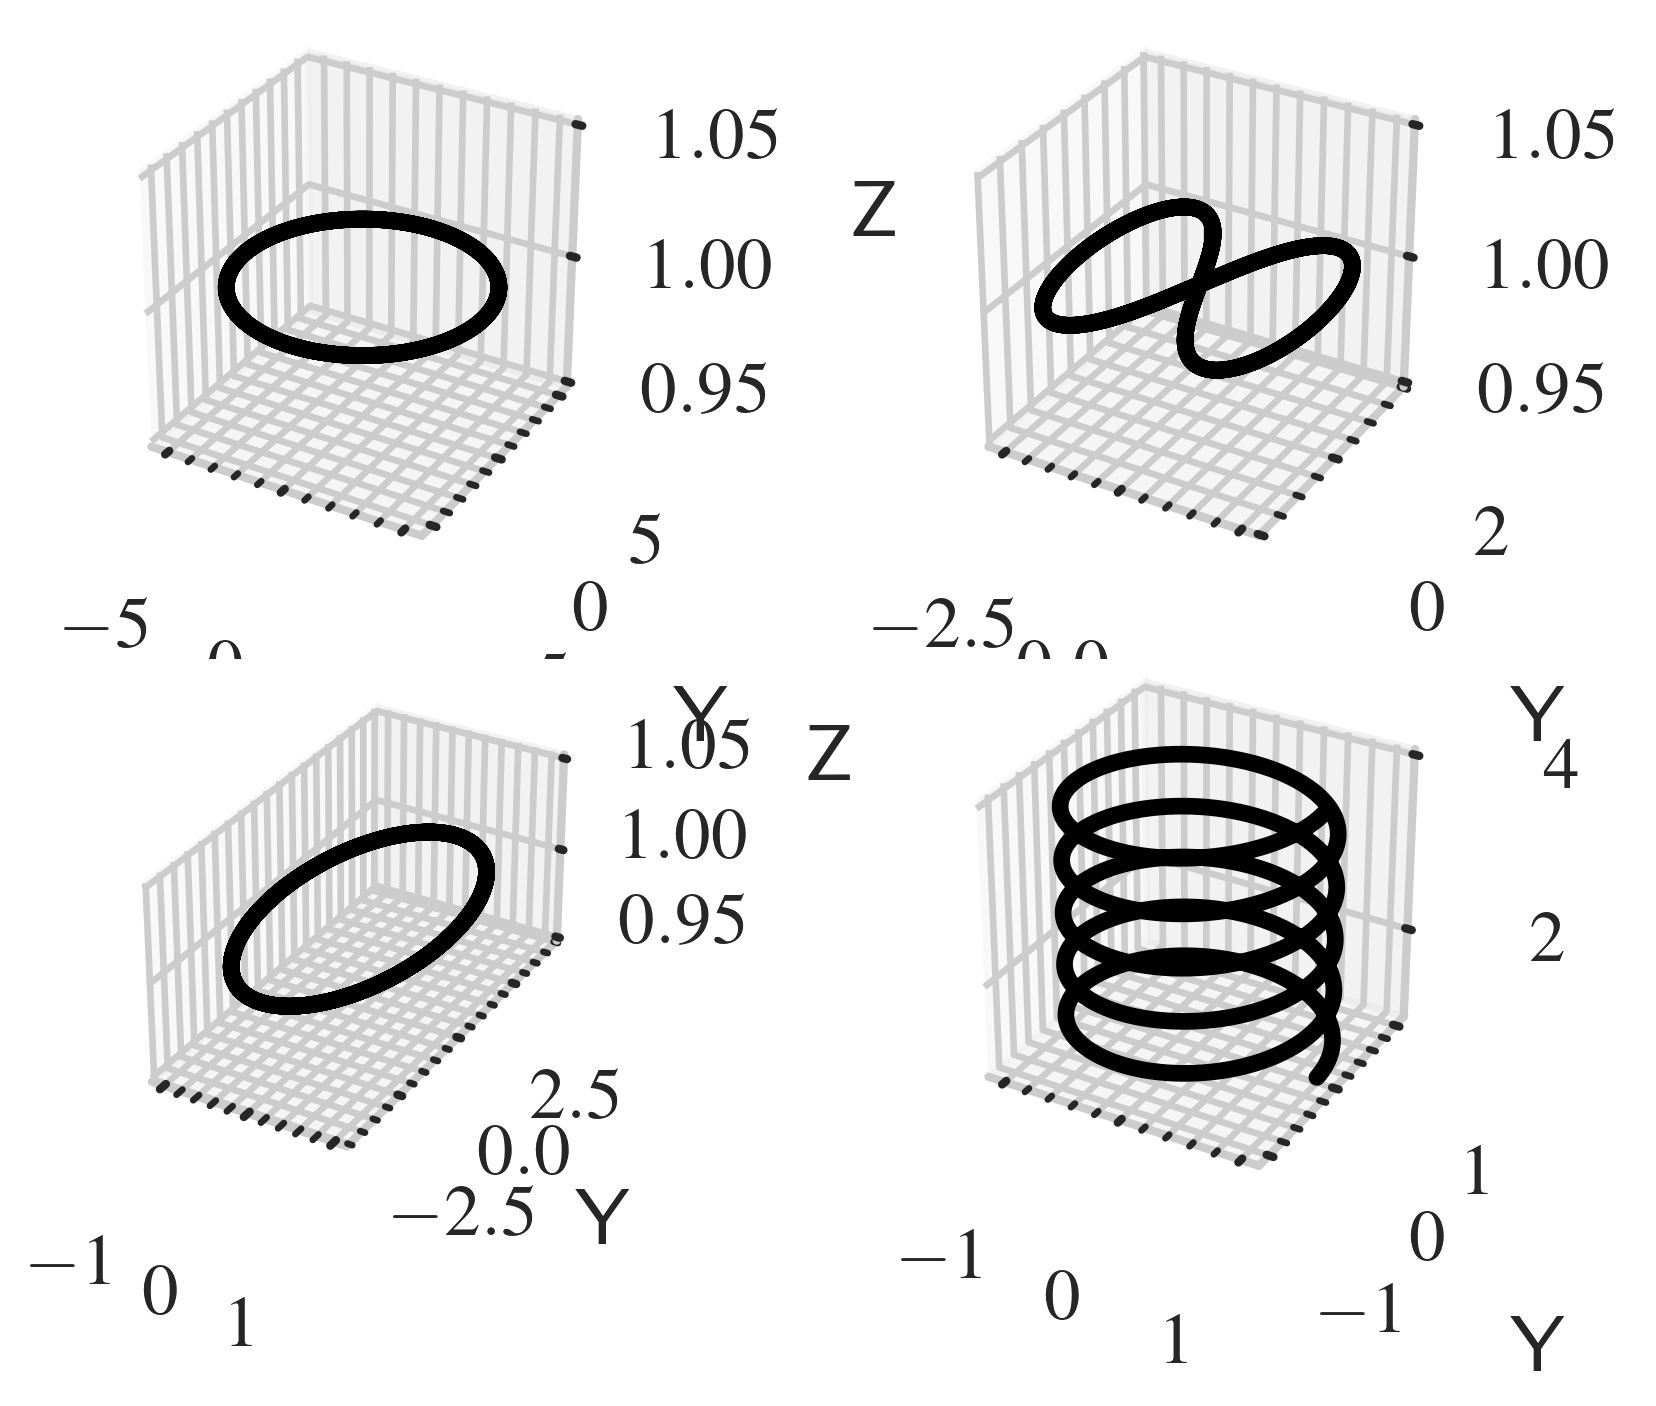

In [6]:
# latex rendering
# plt.rcParams['text.usetex'] = True
# plt.rc('font', family='serif', size=20)

# plot in 3D
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure()


for traj_type in ['circle', 'lemniscate', 'slalom', 'helix']:
    ax = fig.add_subplot(2, 2, ['circle', 'lemniscate', 'slalom', 'helix'].index(traj_type) + 1, projection='3d')
    if traj_type == 'slalom':
        ax.set_box_aspect([1,2,1])
    else:
        ax.set_box_aspect([1, 1, 1])
    points = generator.generate_trajectory(traj_type, T)
    ax.plot(points[:, 0].cpu().numpy(), points[:, 1].cpu().numpy(), points[:, 2].cpu().numpy(), 
            label=traj_type.capitalize(), linewidth=2)

    # ax.set_title('3D Circle Trajectory')
    ax.set_xlabel(r'X')
    ax.set_ylabel(r'Y')
    ax.set_zlabel(r'Z')
    # plt.legend()

# plt.title('3D Trajectories')
# plt.savefig("trajectories_3d.png", dpi=300)
# plt.savefig("trajectories_3d_bigfont.pdf",)

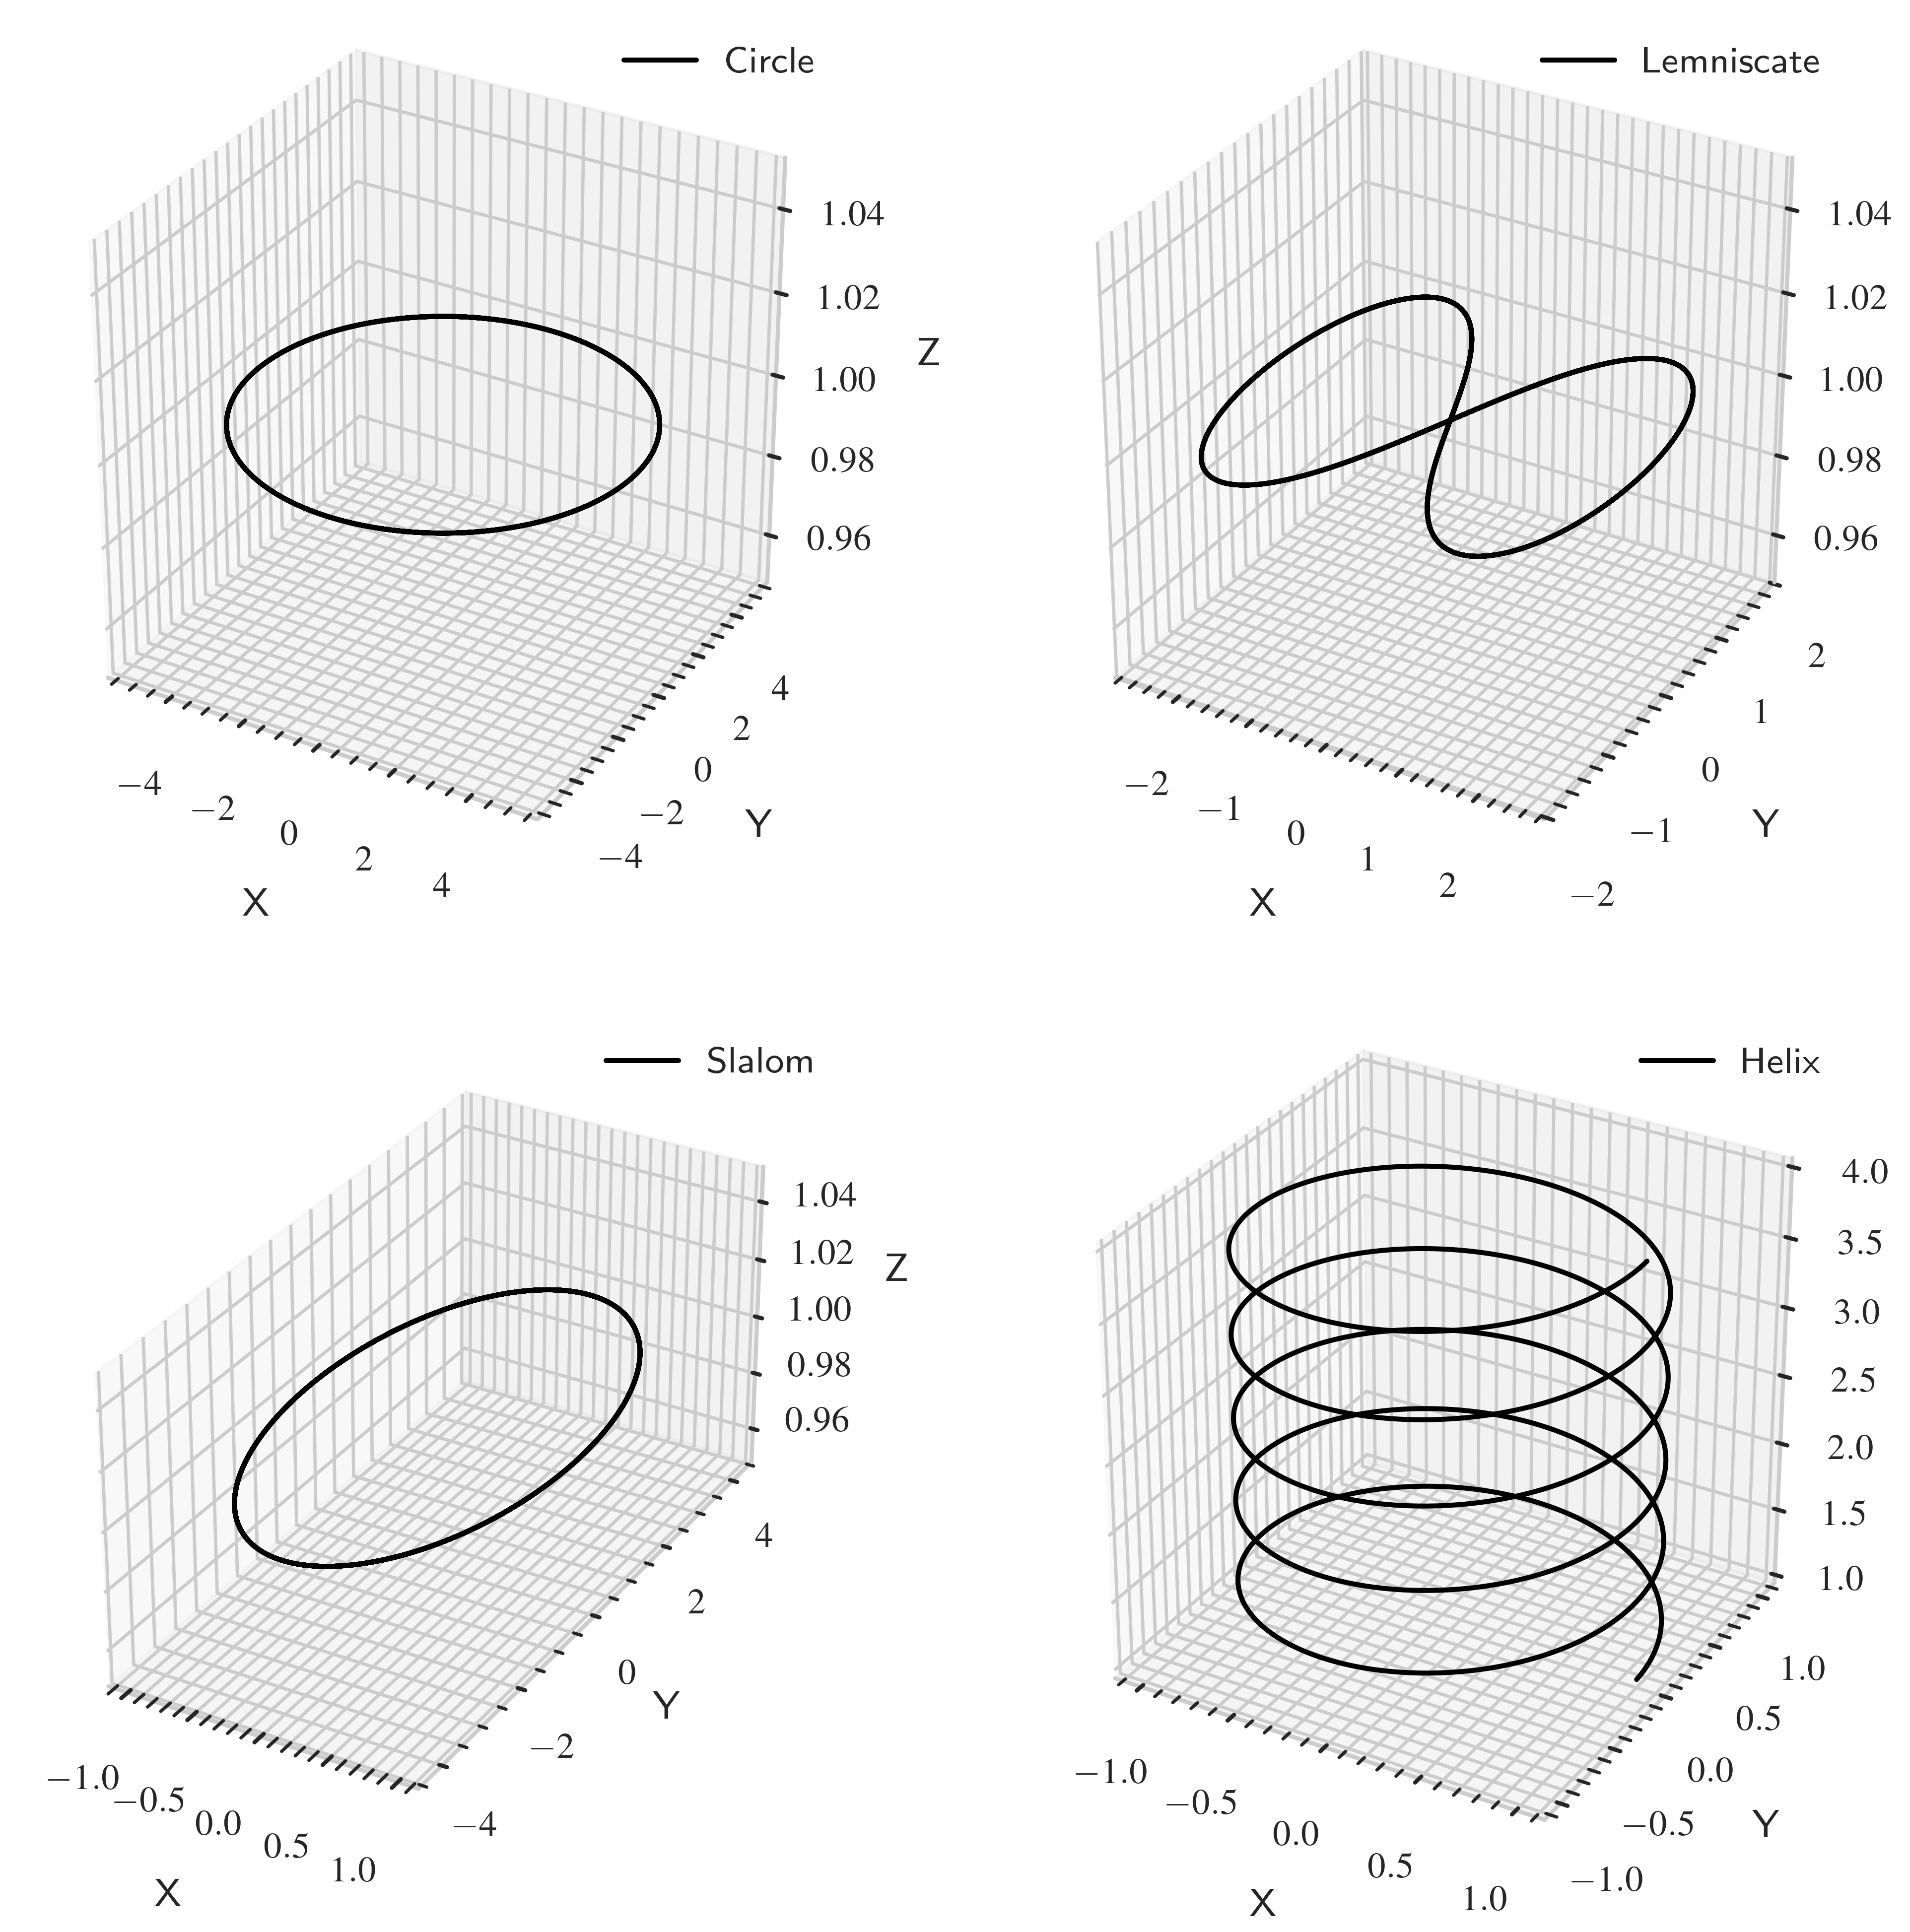

In [11]:
# latex rendering
# plt.rcParams['text.usetex'] = True
# plt.rc('font', family='serif', size=20)

# plot in 3D
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(8, 8))


for traj_type in ['circle', 'lemniscate', 'slalom', 'helix']:
    ax = fig.add_subplot(2, 2, ['circle', 'lemniscate', 'slalom', 'helix'].index(traj_type) + 1, projection='3d')
    if traj_type == 'slalom':
        ax.set_box_aspect([1,2,1])
    else:
        ax.set_box_aspect([1, 1, 1])
    points = generator.generate_trajectory(traj_type, T)
    plt.plot(points[:, 0].cpu().numpy(), points[:, 1].cpu().numpy(), points[:, 2].cpu().numpy(), 
            label=traj_type.capitalize())

    # ax.set_title('3D Circle Trajectory')
    ax.set_xlabel(r'X')
    ax.set_ylabel(r'Y')
    ax.set_zlabel(r'Z')
    plt.legend()

# plt.title('3D Trajectories')
plt.savefig("trajectories_3d.png", dpi=300)
# plt.savefig("trajectories_3d_bigfont.pdf",)

In [12]:
# parametrised tasks
N = 4

heights = torch.rand(N) * 2 + 1  # heights between 1 and 3
radius = torch.rand(N) * 2 + 1  # radius between 1 and 3

fig, ax = plt.subplots(figsize=(6, 6), 2, 2)

for i in range(N):
    generator.params['circle']['height'] = heights[i].item()
    generator.params['circle']['radius'] = radius[i].item()
    pos = generator.circle(T, center=(0.0, 0.0, 1.0))
    print(f"Task {i+1}: Height = {heights[i]:.2f}, Radius = {radius[i]:.2f}, Position = {pos.cpu().numpy()}")
    ax.set_box_aspect([1, 1, 1])
    plt.plot(pos[:, 0].cpu().numpy(), pos[:, 1].cpu().numpy(), label=f'Task {i+1}')
# plot all in subfigures


SyntaxError: positional argument follows keyword argument (2618605595.py, line 7)

Parametrized circle for different parameters


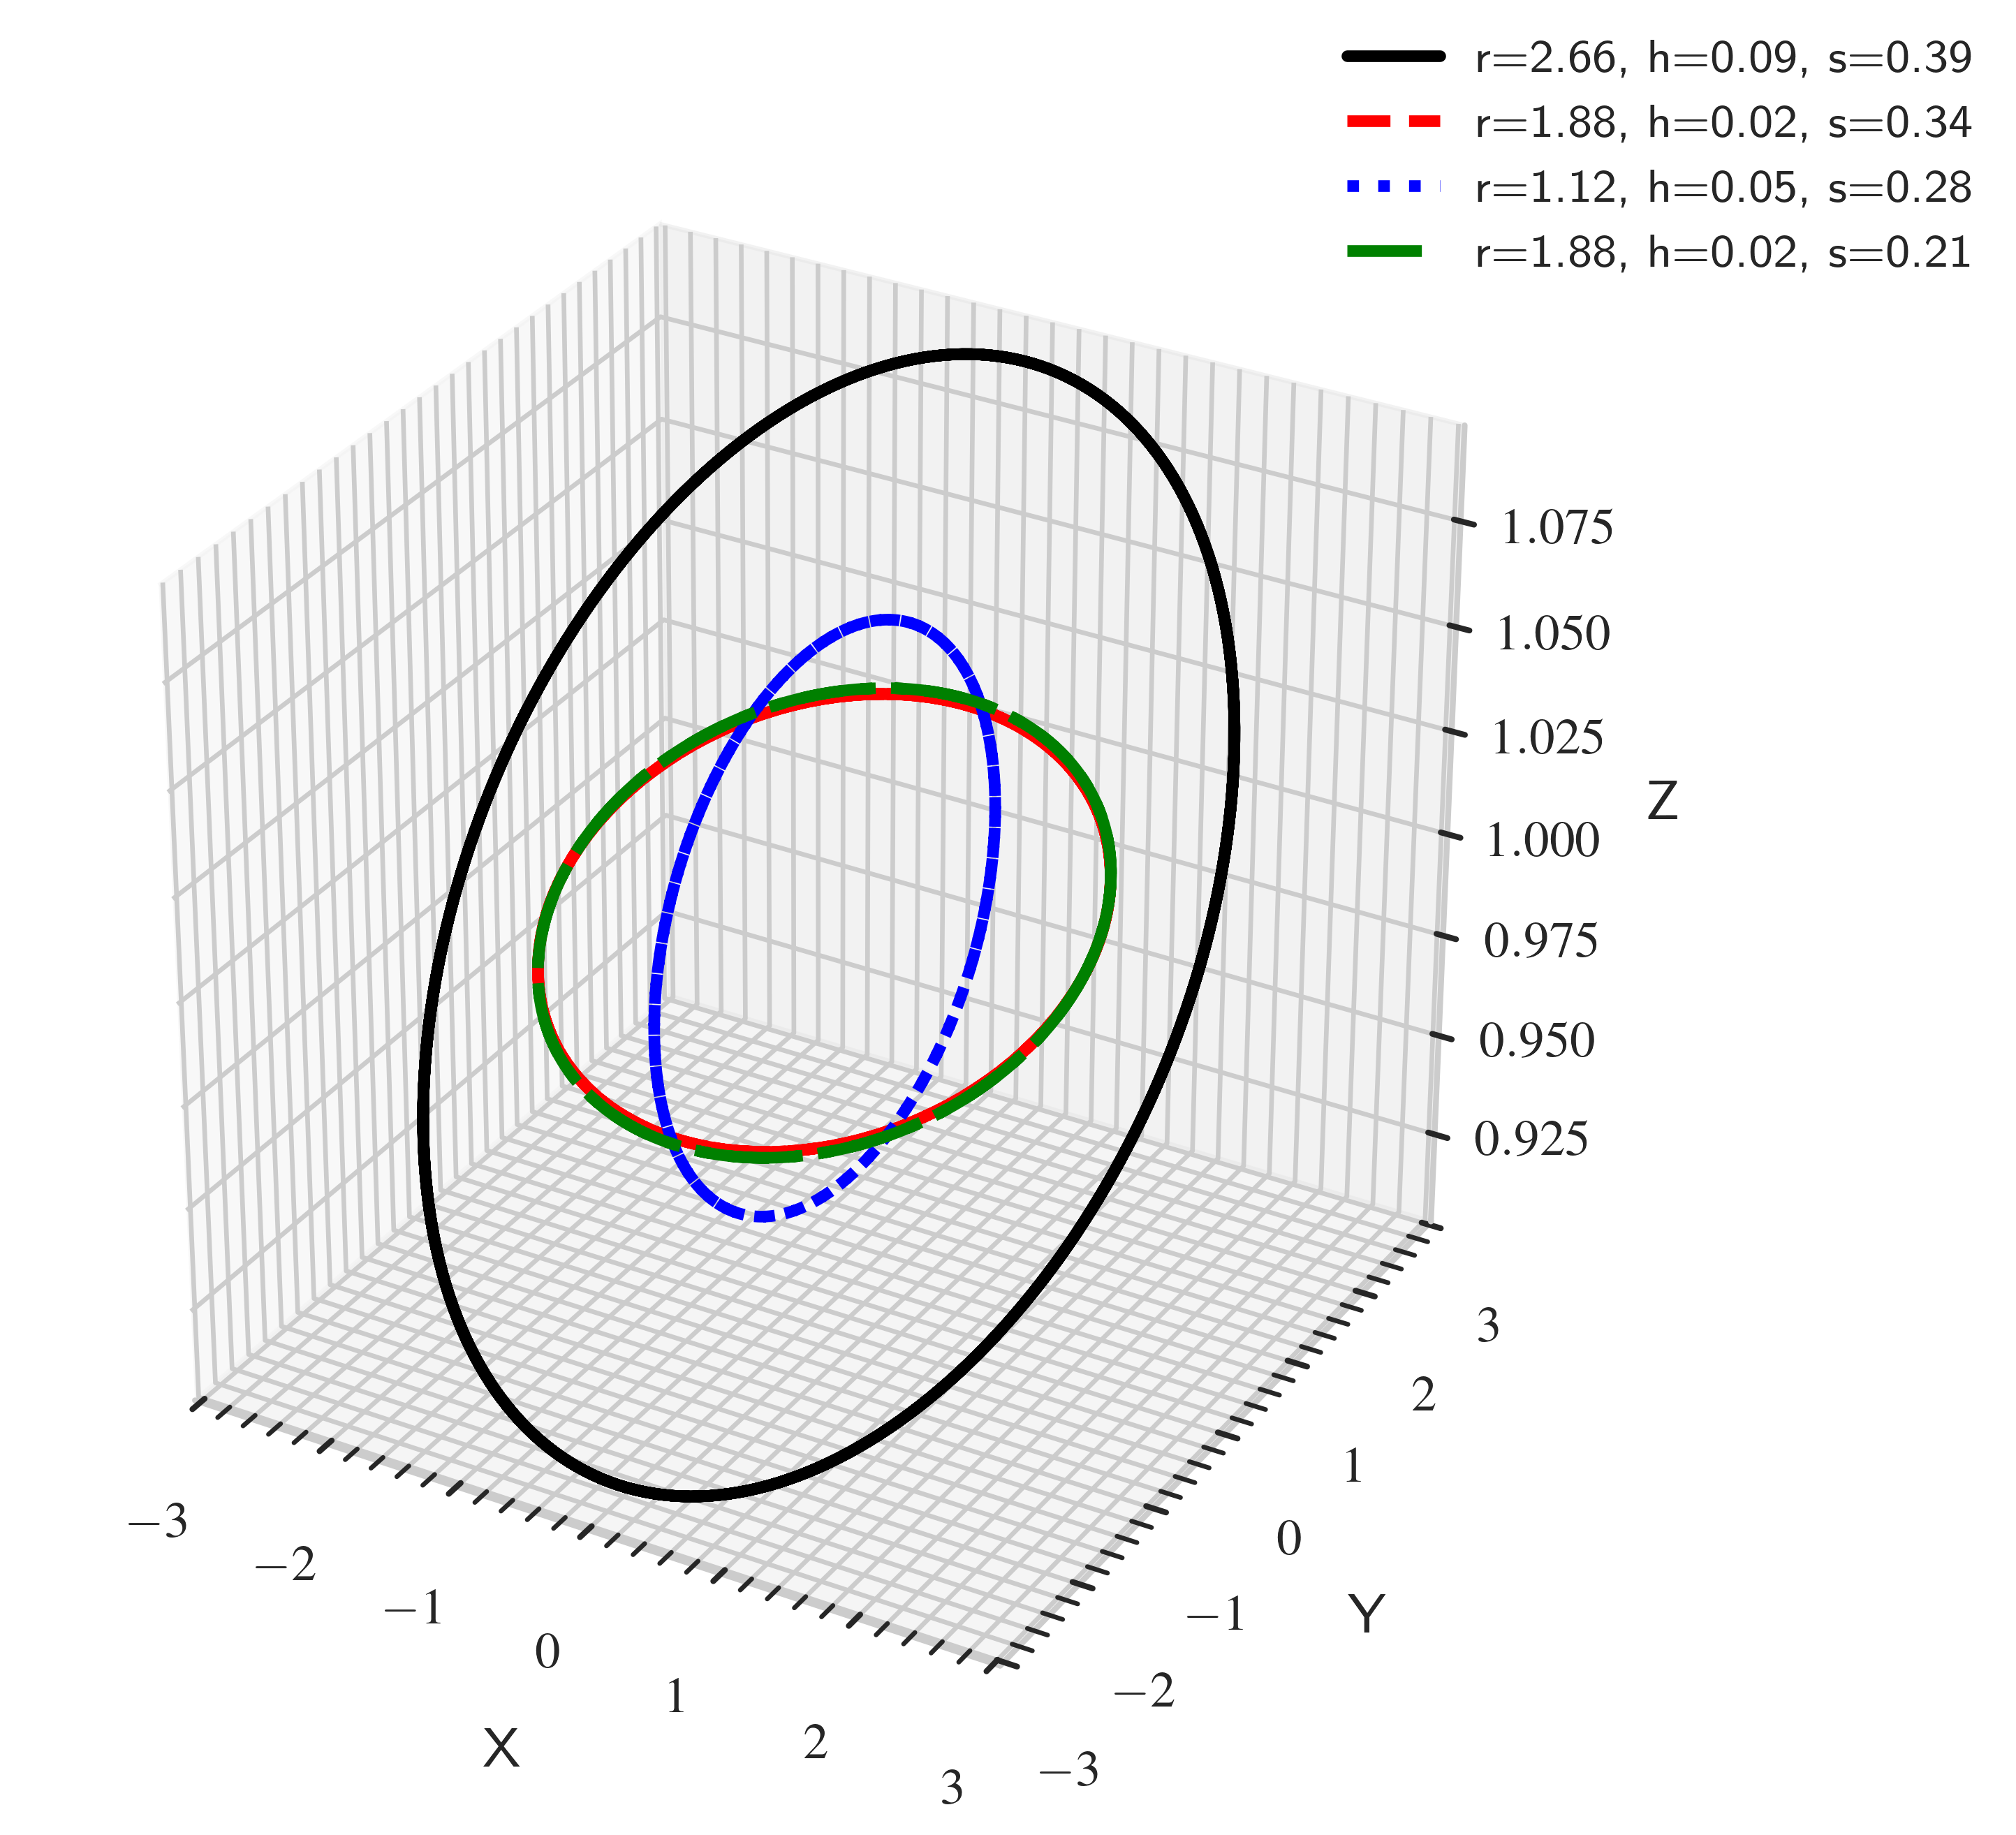

In [13]:
parame_limits = {
    'circle': {
        'radius': (1.0, 3.0),
        'height': (0.01, 0.1),
        'speed': (0.1, 0.4)
    },}

# sample parameters
def sample_parameters(traj_type):
    params = {}
    for param, (low, high) in parame_limits[traj_type].items():
        params[param] = torch.rand(1).item() * (high - low) + low
    return params

# plot cicle with different parameters in the same figure
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(1, 1, 1, projection='3d')
ax.set_box_aspect([1, 1, 1])

for i in range(4):
    params = sample_parameters('circle')
    generator.params['circle'] = params
    pos = generator.circle(T, center=(0.0, 0.0, 1.0))
    ax.plot(pos[:, 0].cpu().numpy(), pos[:, 1].cpu().numpy(), pos[:, 2].cpu().numpy(), 
            label=f"r={params['radius']:.2f}, h={params['height']:.2f}, s={params['speed']:.2f}", linewidth=2)

    # ax.set_title('3D Circle Trajectory')
    ax.set_xlabel(r'X')
    ax.set_ylabel(r'Y')
    ax.set_zlabel(r'Z')
    # plt.legend('upper right', fontsize=8)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='center', borderaxespad=0., fontsize=8)
    plt.tight_layout()

    plt.savefig("trajectories_3d_parametrized_circle.png", dpi=300)

In [ ]:
# legend with square boxes
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0., fontsize=8)
plt.tight_layout()

In [16]:
from trajectory_generator import TrajectoryGenerator

generator = TrajectoryGenerator(device)

In [17]:
time = torch.linspace(0, 10, 1000)
generator.reset(time)

Selected trajectory type: lemniscate


In [21]:
random_time = torch.rand_like(time) * 10.0

generator.generate_trajectory("lemniscate", random_time)

tensor([[-0.5439, -1.0586,  1.6146],
        [-0.8712, -0.9478,  2.4791],
        [-0.7637,  1.0154,  1.5454],
        ...,
        [-1.8896, -0.6904,  2.0311],
        [-0.5871,  1.0606,  2.4007],
        [-2.1495,  0.9631,  1.8437]], device='cuda:0')

In [1]:
import torch

In [ ]:
# create 2 layyer neural network
neural_net = torch.nn.Sequential(
    torch.nn.Linear(3, 4),
    torch.nn.ReLU(),
    torch.nn.Linear(4, 2)
)   

nerual_net_0 = torch.nn.Sequential(
    torch.nn.Linear(3, 4),
    torch.nn.ReLU(),
    torch.nn.Linear(4, 2)
)

# initialize both with same weights
for param, param_0 in zip(neural_net.parameters(), nerual_net_0.parameters()):
    param.data.copy_(param_0.data)

# # take difference of parameters
# for (name, param), (name_0, param_0) in zip(neural_net.named_parameters(), nerual_net_0.named_parameters()):
#     if name == name_0:
#         diff = param.data - param_0.data
#         print(f"Layer: {name}, Shape: {param.shape}")
#         print(diff)

Layer: 0.weight, Shape: torch.Size([4, 3])
tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
Layer: 0.bias, Shape: torch.Size([4])
tensor([0., 0., 0., 0.])
Layer: 2.weight, Shape: torch.Size([2, 4])
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.]])
Layer: 2.bias, Shape: torch.Size([2])
tensor([0., 0.])


In [10]:

for k, v in neural_net.named_parameters():
    print(f"Layer: {k}, Shape: {v.shape}")
    layer_norm = torch.norm(v).item()
    print(f"Layer: {k}, Norm: {layer_norm}")


Layer: 0.weight, Shape: torch.Size([4, 3])
Layer: 0.weight, Norm: 1.3107385635375977
Layer: 0.bias, Shape: torch.Size([4])
Layer: 0.bias, Norm: 0.6827098727226257
Layer: 2.weight, Shape: torch.Size([2, 4])
Layer: 2.weight, Norm: 1.04303777217865
Layer: 2.bias, Shape: torch.Size([2])
Layer: 2.bias, Norm: 0.2694331705570221


In [8]:
# print parameters
for k, v in neural_net.named_parameters():
    print(f"Layer: {k}, Shape: {v.shape}")
    print(v)

Layer: 0.weight, Shape: torch.Size([4, 3])
Parameter containing:
tensor([[ 0.1798, -0.1676, -0.2103],
        [ 0.3664,  0.0806,  0.3987],
        [ 0.1313, -0.5425, -0.1539],
        [-0.1999,  0.0134,  0.1288]], requires_grad=True)
Layer: 0.bias, Shape: torch.Size([4])
Parameter containing:
tensor([-0.4383, -0.5054, -0.5448,  0.4834], requires_grad=True)
Layer: 2.weight, Shape: torch.Size([2, 4])
Parameter containing:
tensor([[-0.0043,  0.0931,  0.4141, -0.1870],
        [-0.3023, -0.2043,  0.1140, -0.4265]], requires_grad=True)
Layer: 2.bias, Shape: torch.Size([2])
Parameter containing:
tensor([-0.0721, -0.0819], requires_grad=True)
